In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("weatherAUS.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (145460, 23)


In [6]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


In [8]:
df["Location"].unique()

<StringArray>
[          'Albury',    'BadgerysCreek',            'Cobar',
     'CoffsHarbour',            'Moree',        'Newcastle',
        'NorahHead',    'NorfolkIsland',          'Penrith',
         'Richmond',           'Sydney',    'SydneyAirport',
       'WaggaWagga',      'Williamtown',       'Wollongong',
         'Canberra',      'Tuggeranong',      'MountGinini',
         'Ballarat',          'Bendigo',             'Sale',
 'MelbourneAirport',        'Melbourne',          'Mildura',
             'Nhil',         'Portland',         'Watsonia',
         'Dartmoor',         'Brisbane',           'Cairns',
        'GoldCoast',       'Townsville',         'Adelaide',
     'MountGambier',        'Nuriootpa',          'Woomera',
           'Albany',      'Witchcliffe',       'PearceRAAF',
     'PerthAirport',            'Perth',       'SalmonGums',
          'Walpole',           'Hobart',       'Launceston',
     'AliceSprings',           'Darwin',        'Katherine',
          

In [9]:
cities = [
    "Sydney",
    "Melbourne",
    "Brisbane",
    "Perth",
    "Adelaide"
]

In [10]:
df = df[df["Location"].isin(cities)].copy()

In [11]:
df["Location"].value_counts()

Location
Sydney       3344
Melbourne    3193
Brisbane     3193
Adelaide     3193
Perth        3193
Name: count, dtype: int64

In [12]:
df["Date"] = pd.to_datetime(df["Date"])

In [13]:
df["Date"].min(), df["Date"].max()

(Timestamp('2008-02-01 00:00:00'), Timestamp('2017-06-25 00:00:00'))

In [14]:
print(df["Date"].min())
print(df["Date"].max())

2008-02-01 00:00:00
2017-06-25 00:00:00


In [15]:
df = df[
    (df["Date"] >= "2013-01-01") &
    (df["Date"] <= "2017-12-31")
].copy()

In [16]:
print(df["Date"].min())
print(df["Date"].max())
print(df.shape)

2013-01-01 00:00:00
2017-06-25 00:00:00
(8045, 23)


In [17]:
df["Temperature"] = (
    df["MinTemp"] + df["MaxTemp"]
) / 2

In [18]:
df["Humidity"] = (
    df["Humidity9am"] + df["Humidity3pm"]
) / 2

In [19]:
df["WindSpeed"] = (
    df["WindSpeed9am"] + df["WindSpeed3pm"]
) / 2

In [20]:
df[
    [
        "Date",
        "Location",
        "Temperature",
        "Humidity",
        "WindSpeed",
        "Rainfall"
    ]
].head()

,Date,Location,Temperature,Humidity,WindSpeed,Rainfall
31911,2013-01-01,Sydney,23.20,69.0,14.0,0.0
31912,2013-01-02,Sydney,21.60,65.5,20.5,0.0
31913,2013-01-03,Sydney,21.60,54.0,13.0,0.0
31914,2013-01-04,Sydney,22.45,59.5,21.5,0.0
31915,2013-01-05,Sydney,24.60,56.0,13.0,0.0


In [21]:
weather_cols = [
    "Temperature",
    "Humidity",
    "WindSpeed",
    "Rainfall"
]

df[weather_cols].isnull().sum()

Temperature    500
Humidity       497
WindSpeed        7
Rainfall       703
dtype: int64

In [22]:
df = df.sort_values(
    ["Location", "Date"]
)

In [23]:
df[weather_cols] = (
    df.groupby("Location")[weather_cols]
      .ffill()
)

In [24]:
df[weather_cols].isnull().sum()

Temperature    0
Humidity       0
WindSpeed      0
Rainfall       0
dtype: int64

In [25]:
from scipy import stats

In [27]:
for city in cities:
    city_mask = df["Location"] == city

    for col in weather_cols:
        values = df.loc[city_mask, col]

        z_scores = np.abs(
            stats.zscore(values, nan_policy="omit")
        )

        df.loc[city_mask, f"{col}_zscore"] = z_scores

In [28]:
for col in weather_cols:
    df = df[
        (df[f"{col}_zscore"] < 3) |
        (df[f"{col}_zscore"].isna())
    ]

In [29]:
zscore_columns = [
    col for col in df.columns
    if col.endswith("_zscore")
]

df.drop(
    columns=zscore_columns,
    inplace=True
)

In [30]:
df = df.set_index("Date")

In [31]:
monthly = (
    df.groupby("Location")[weather_cols]
      .resample("ME")
      .mean()
      .reset_index()
)

In [32]:
monthly.head()

,Location,Date,Temperature,Humidity,WindSpeed,Rainfall
0,Adelaide,2013-01-31,23.545161,37.935484,14.483871,0.374194
1,Adelaide,2013-02-28,NaN,NaN,NaN,NaN
2,Adelaide,2013-03-31,23.350000,46.966667,13.150000,0.653333
3,Adelaide,2013-04-30,18.551667,50.900000,11.766667,1.106667
4,Adelaide,2013-05-31,16.551667,53.683333,12.066667,1.300000


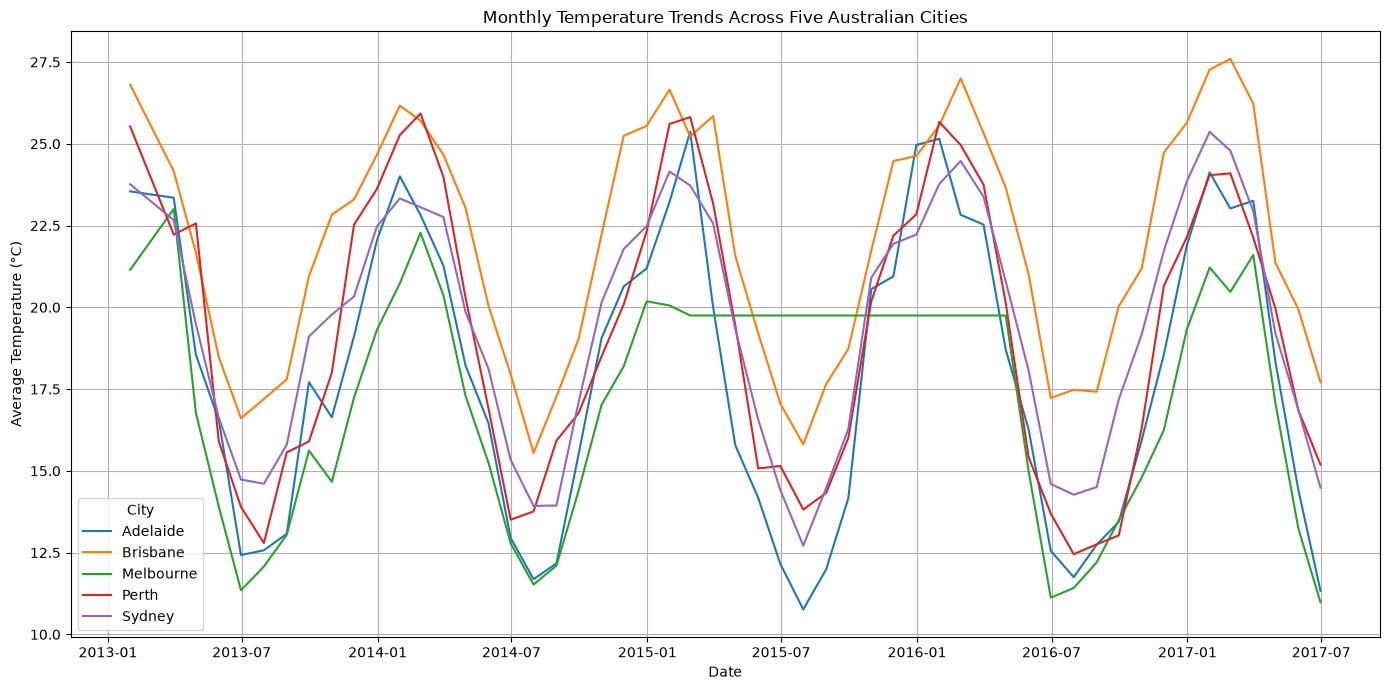

In [33]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly,
    x="Date",
    y="Temperature",
    hue="Location"
)

plt.title(
    "Monthly Temperature Trends Across Five Australian Cities"
)

plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")

plt.legend(title="City")

plt.grid(True)

plt.tight_layout()

plt.show()

In [34]:
monthly["Month"] = monthly["Date"].dt.month

In [35]:
rainfall_pivot = monthly.pivot_table(
    index="Month",
    columns="Location",
    values="Rainfall"
)

In [36]:
rainfall_pivot

Location,Adelaide,Brisbane,Melbourne,Perth,Sydney
Month,,,,,
1,0.613965,1.882128,0.293355,0.356516,2.536810
2,0.267219,1.195924,0.176068,0.425212,2.357606
3,0.436869,2.185741,0.467113,0.538687,3.590251
4,1.070023,1.201524,0.845985,0.956414,3.680858
5,1.168276,0.880537,1.043699,1.831947,1.836129
6,1.203839,1.454921,1.273997,1.493296,2.126438
7,2.187077,0.687677,0.899781,2.936190,1.624194
8,1.470323,0.854032,1.164074,2.558161,2.061826
9,1.016048,1.235057,1.106746,2.563506,1.988448


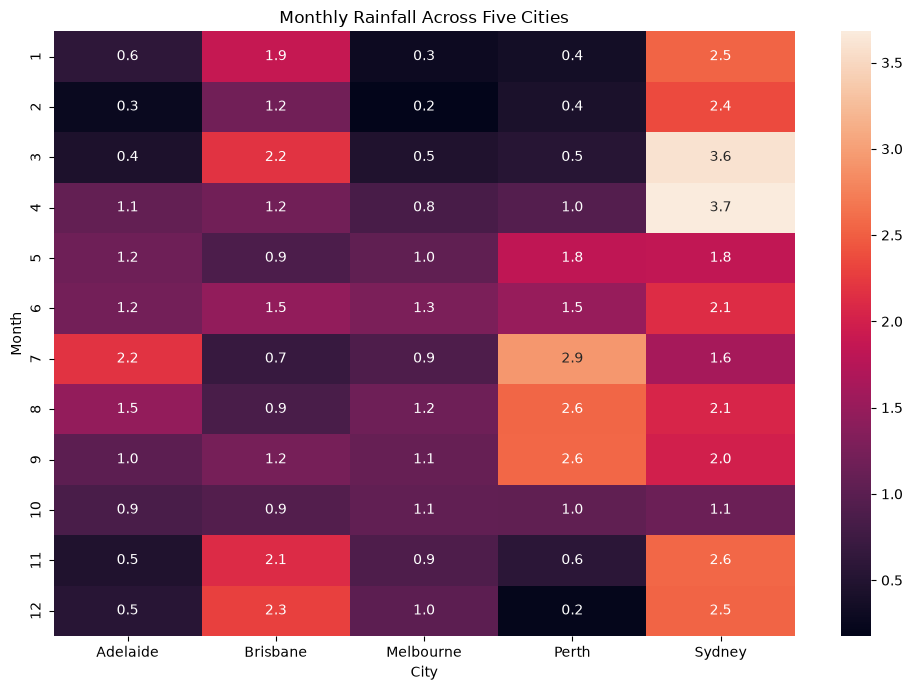

In [37]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    rainfall_pivot,
    annot=True,
    fmt=".1f"
)

plt.title(
    "Monthly Rainfall Across Five Cities"
)

plt.xlabel("City")
plt.ylabel("Month")

plt.tight_layout()

plt.show()

In [38]:
def get_season(month):

    if month in [12, 1, 2]:
        return "Summer"

    elif month in [3, 4, 5]:
        return "Autumn"

    elif month in [6, 7, 8]:
        return "Winter"

    else:
        return "Spring"

In [39]:
monthly["Season"] = monthly["Month"].apply(
    get_season
)

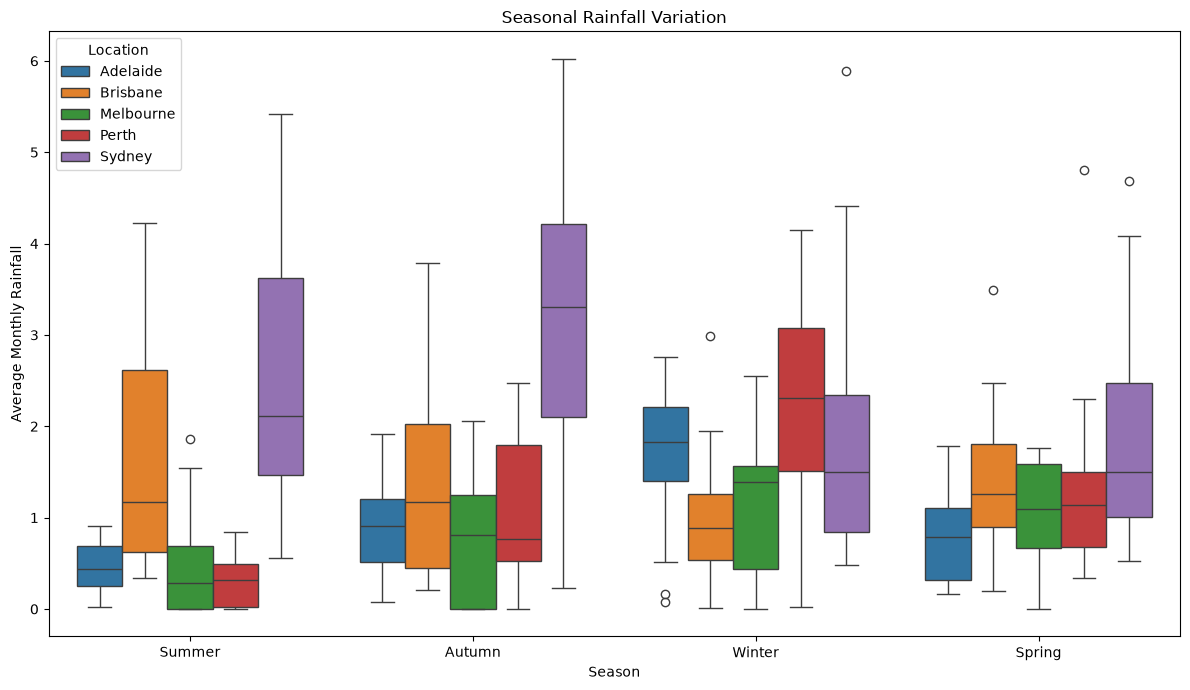

In [40]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=monthly,
    x="Season",
    y="Rainfall",
    hue="Location"
)

plt.title(
    "Seasonal Rainfall Variation"
)

plt.xlabel("Season")
plt.ylabel("Average Monthly Rainfall")

plt.tight_layout()

plt.show()

In [41]:
coords = {
    "Sydney": (-33.8688, 151.2093),
    "Melbourne": (-37.8136, 144.9631),
    "Brisbane": (-27.4698, 153.0251),
    "Perth": (-31.9505, 115.8605),
    "Adelaide": (-34.9285, 138.6007)
}

In [42]:
m = folium.Map(
    location=[-25, 133],
    zoom_start=4
)

In [43]:
for city, (lat, lon) in coords.items():

    city_data = monthly[
        monthly["Location"] == city
    ]

    avg_temp = city_data["Temperature"].mean()
    avg_rain = city_data["Rainfall"].mean()
    avg_humidity = city_data["Humidity"].mean()

    popup = f"""
    <b>{city}</b><br>
    Average Temperature: {avg_temp:.2f} °C<br>
    Average Humidity: {avg_humidity:.2f}%<br>
    Average Rainfall: {avg_rain:.2f} mm
    """

    folium.CircleMarker(
        location=[lat, lon],
        radius=8,
        popup=popup,
        tooltip=city,
        fill=True
    ).add_to(m)

In [44]:
m.save("rainfall_map.html")

In [45]:
from sklearn.linear_model import LinearRegression

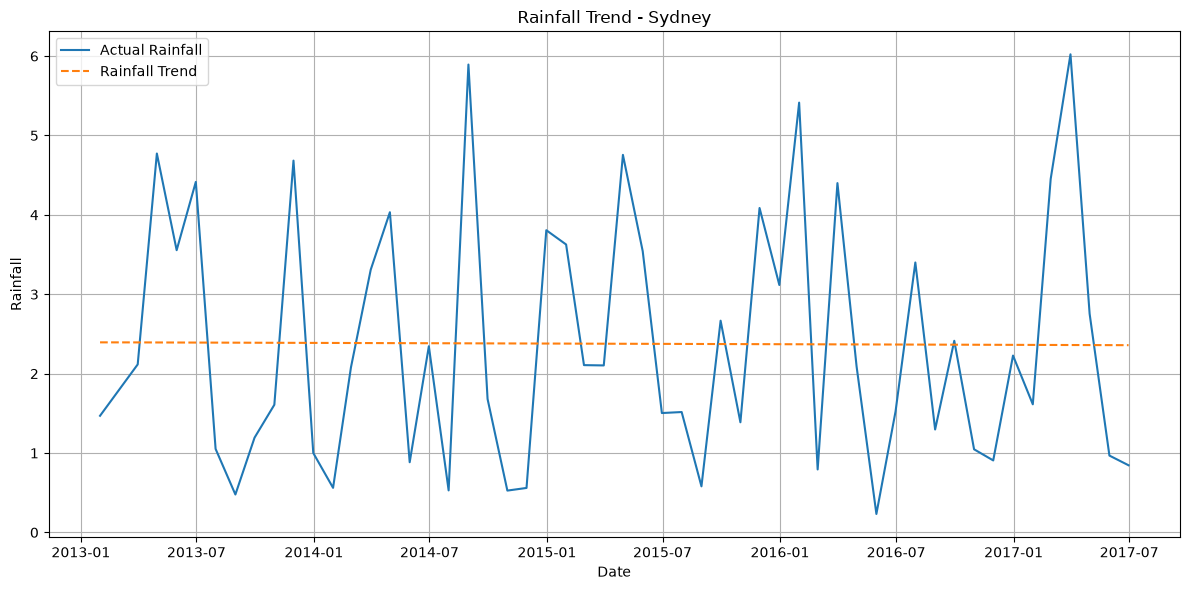

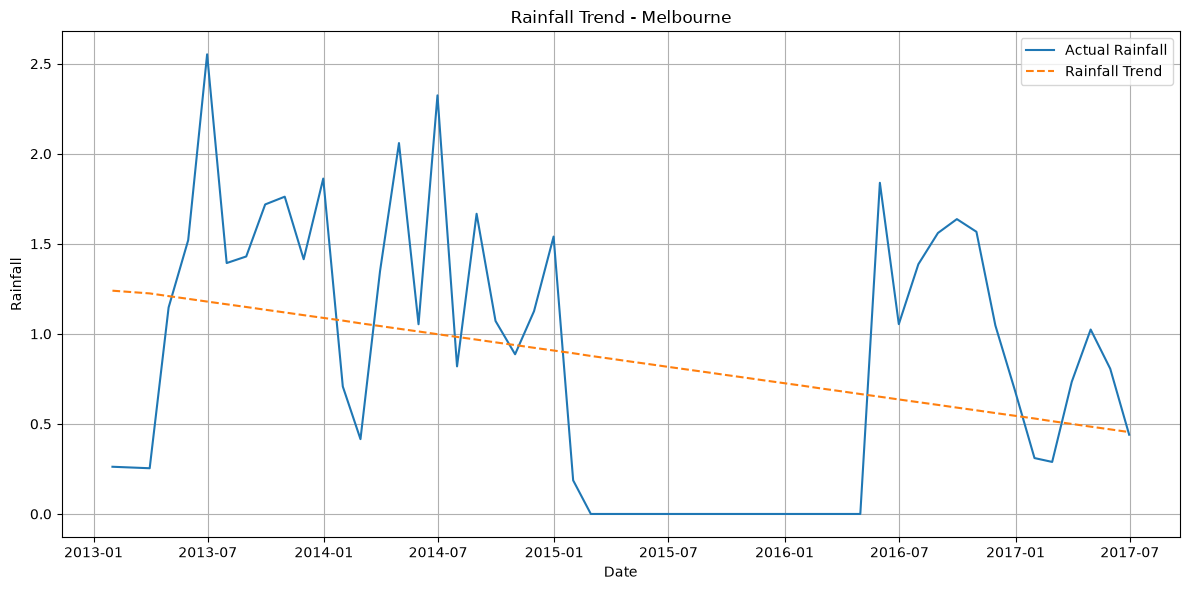

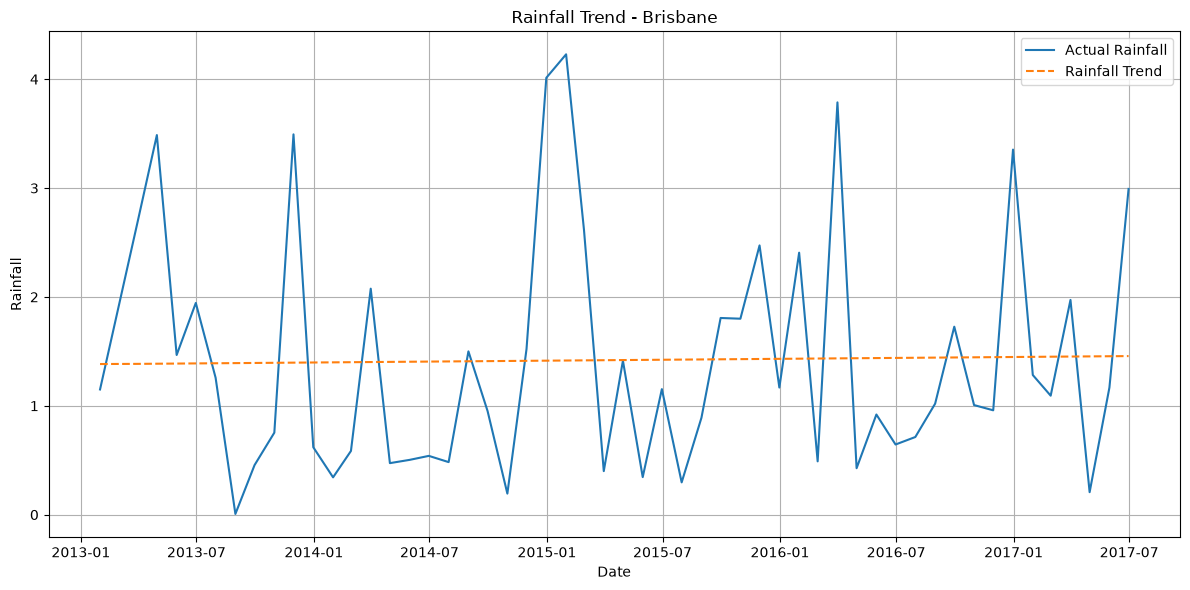

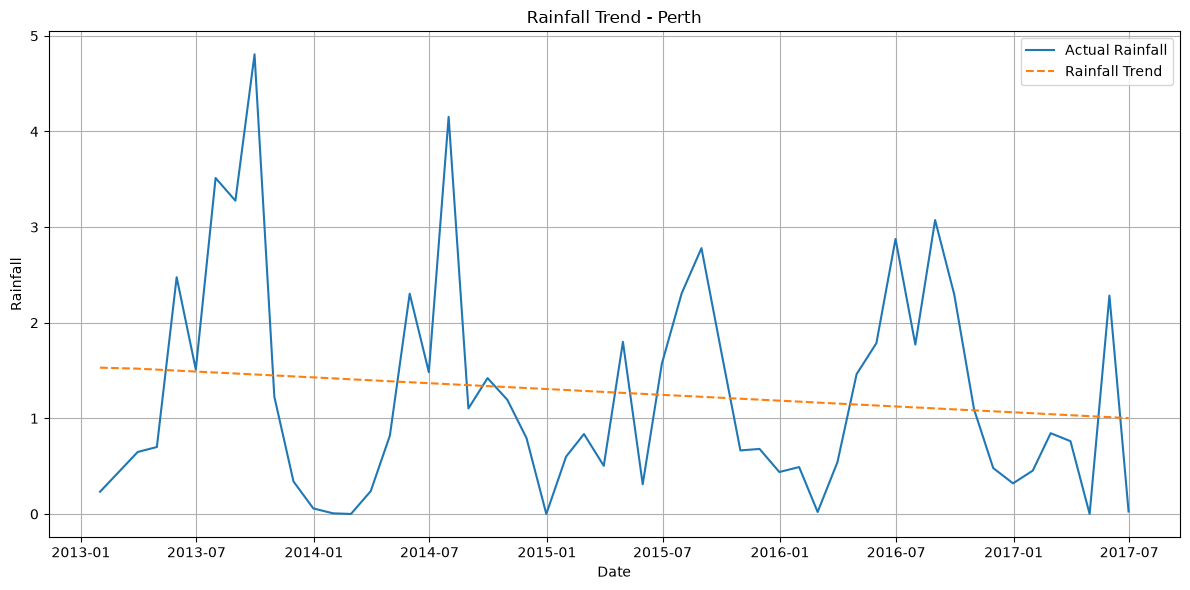

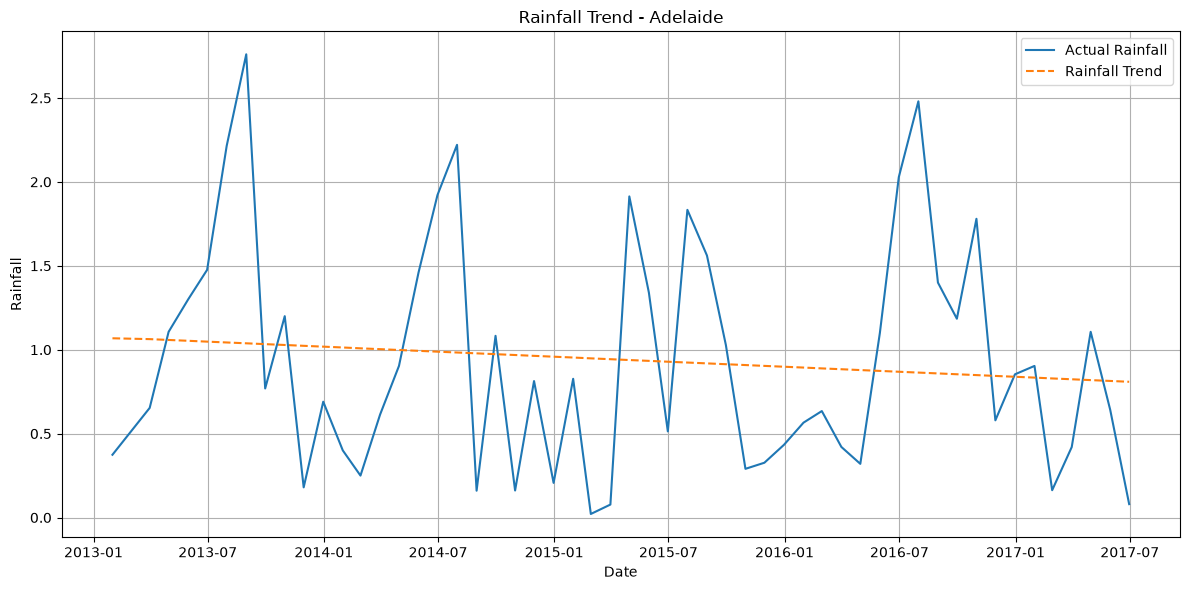

In [46]:
for city in cities:

    sub = monthly[
        monthly["Location"] == city
    ].dropna(subset=["Rainfall"]).copy()

    X = np.arange(
        len(sub)
    ).reshape(-1, 1)

    y = sub["Rainfall"].values

    model = LinearRegression()

    model.fit(X, y)

    trend = model.predict(X)

    plt.figure(figsize=(12, 6))

    plt.plot(
        sub["Date"],
        y,
        label="Actual Rainfall"
    )

    plt.plot(
        sub["Date"],
        trend,
        linestyle="--",
        label="Rainfall Trend"
    )

    plt.title(
        f"Rainfall Trend - {city}"
    )

    plt.xlabel("Date")
    plt.ylabel("Rainfall")

    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    plt.show()

In [50]:
import os

print("Notebook is running from:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Notebook is running from:
d:\Projects\Weather-Pattern-Analysis

Files/folders here:
['outputs', 'rainfall_map.html', 'weatherAUS.csv', 'weather_analysis.ipynb']


In [51]:
import os

os.makedirs("outputs", exist_ok=True)

print("Outputs folder created!")
print("Does it exist?", os.path.exists("outputs"))

Outputs folder created!
Does it exist? True


In [52]:
print(os.path.abspath("outputs"))

d:\Projects\Weather-Pattern-Analysis\outputs


In [53]:
plt.savefig(
    "outputs/temperature_trends.png",
    dpi=300,
    bbox_inches="tight"
)

print("Temperature graph saved successfully!")

Temperature graph saved successfully!


<Figure size 640x480 with 0 Axes>